# TRI Baseline Comparisons

Compares text representations for predicting patent–paper-pair membership:

| Representation | Classifiers |
|---|---|
| Bag-of-words (counts) | Naive Bayes, Logistic Regression, XGBoost |
| TF-IDF (1–2 grams) | Logistic Regression, XGBoost |
| MiniLM (general-purpose encoder) | Logistic Regression, XGBoost |
| SciBERT | Logistic Regression, XGBoost |
| SPECTER2 (precomputed or recomputed) | Logistic Regression, XGBoost |

**Evaluation:** stratified 5-fold CV ROC-AUC / PR-AUC, a fixed holdout split for ROC curves, and a paired bootstrap test of the best embedding model vs. the best sparse baseline.

**Input:** a CSV with columns `title`, `abstract`, `label` (1 = patent–paper pair, 0 = comparison), optionally `publication_year` for the temporal holdout.

Set your paths in the **Configuration** cell, then Run All.

In [ ]:
# Install dependencies (run once, then restart the kernel if prompted)
# %pip install scikit-learn xgboost pandas numpy matplotlib torch transformers adapters sentence-transformers

In [1]:
import hashlib
import json
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm

from sklearn.base import clone
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
%matplotlib inline
plt.rcParams['figure.dpi'] = 300

/opt/anaconda3/lib/python3.8/site-packages/xgboost/compat.py:31: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index


## Configuration

Edit these before running. If you already have SPECTER2 embeddings, set `SPECTER2_FILE` — the file must be **row-aligned** with `DATA_PATH` (row *i* of the embeddings is the paper in row *i* of the CSV).

In [2]:
DATA_PATH = "Data/tri_dataset.csv"          # CSV with title, abstract, label
OUTDIR = "Data"                      # output folder
SPECTER2_FILE = "Data/specter2_embeddings.npy"  # or None to recompute from scratch
SKIP = []                               # e.g. ["SciBERT"] to skip slow models

RANDOM_STATE = 42
N_FOLDS = 5
TEST_SIZE = 0.20
N_BOOTSTRAP = 2000
TEMPORAL_CUTOFF = None   # e.g. 2020 -> train on <=2020, test on later papers

EMBEDDING_BATCH_SIZE = 32
MAX_LENGTH = 512

os.makedirs(OUTDIR, exist_ok=True)
CACHE_DIR = os.path.join(OUTDIR, "emb_cache")
os.makedirs(CACHE_DIR, exist_ok=True)

## 1. Load data

In [3]:
df = pd.read_csv(DATA_PATH)
required = {"title", "abstract", "label"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Input CSV missing columns: {missing}")

n_before = len(df)
df = df.dropna(subset=["title", "label"]).reset_index(drop=True)
if len(df) != n_before:
    print(f"WARNING: dropped {n_before - len(df)} rows with missing title/label. "
          "If using a precomputed embedding file, it must align with the CLEANED rows.")
df["abstract"] = df["abstract"].fillna("")
df["text"] = (df["title"].str.strip() + ". " + df["abstract"].str.strip()).str.strip()
df["label"] = df["label"].astype(int)
y = df["label"].to_numpy()

print(f"Loaded {len(df)} publications "
      f"({df.label.sum()} positive / {(1 - df.label).sum()} comparison)")
df.head(3)

Loaded 20610 publications (9431 positive / 11179 comparison)


,id,title,abstract,label,text
0,https://openalex.org/W2972368829,High-performance organic light-emitting diodes...,Organic light-emitting diode (OLED) technology...,1,High-performance organic light-emitting diodes...
1,https://openalex.org/W2952991341,lEarn,We aim to increase the profit of a given gener...,1,lEarn. We aim to increase the profit of a give...
2,https://openalex.org/W3107984346,Bidding Strategy for Two-Sided Electricity Mar...,We aim to increase the revenue or reduce the p...,1,Bidding Strategy for Two-Sided Electricity Mar...


## 2. Embedding functions

Embeddings are cached to `.npy` files keyed by a hash of the texts, so re-running the notebook is cheap. `load_precomputed` handles your existing SPECTER2 file.

In [4]:
def _cache_path(name, texts):
    h = hashlib.sha256("\x1e".join(texts).encode("utf-8")).hexdigest()[:16]
    return os.path.join(CACHE_DIR, f"{name}_{h}.npy")


def load_precomputed(path, n_expected):
    """Load precomputed embeddings from .npy, .npz, .csv, .parquet, or .pkl.
    Rows MUST be in the same order as the dataset. Non-numeric columns
    (ids, titles) in csv/parquet are dropped automatically."""
    ext = os.path.splitext(path)[1].lower()
    if ext == ".npy":
        emb = np.load(path)
    elif ext == ".npz":
        data = np.load(path)
        emb = data[list(data.keys())[0]]
    elif ext in (".csv", ".parquet", ".pkl"):
        edf = (pd.read_csv(path) if ext == ".csv"
               else pd.read_parquet(path) if ext == ".parquet"
               else pd.read_pickle(path))
        emb = edf.select_dtypes(include=[np.number]).to_numpy()
    else:
        raise ValueError(f"Unsupported embedding file type: {ext}")
    emb = np.asarray(emb, dtype=np.float32)
    if emb.shape[0] != n_expected:
        raise ValueError(
            f"Embedding rows ({emb.shape[0]}) != dataset rows ({n_expected}). "
            "The embedding file must be row-aligned with the input CSV.")
    print(f"Loaded precomputed embeddings: {emb.shape} from {path}")
    return emb


def embed_minilm(texts):
    path = _cache_path("minilm", texts)
    if os.path.exists(path):
        return np.load(path)
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    emb = model.encode(texts, batch_size=EMBEDDING_BATCH_SIZE,
                       show_progress_bar=True, convert_to_numpy=True)
    np.save(path, emb)
    return emb


def _hf_embed(texts, tokenizer, model, device, pooling="cls"):
    import torch
    model.to(device).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), EMBEDDING_BATCH_SIZE):
            batch = texts[i:i + EMBEDDING_BATCH_SIZE]
            enc = tokenizer(batch, padding=True, truncation=True,
                            max_length=MAX_LENGTH, return_tensors="pt").to(device)
            hidden = model(**enc).last_hidden_state
            if pooling == "cls":
                vec = hidden[:, 0, :]
            else:  # mean pooling over non-padding tokens
                mask = enc["attention_mask"].unsqueeze(-1)
                vec = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1)
            out.append(vec.cpu().numpy())
            if (i // EMBEDDING_BATCH_SIZE) % 20 == 0:
                print(f"  embedded {i + len(batch)}/{len(texts)}")
    return np.vstack(out)


def embed_scibert(df):
    texts = df["text"].tolist()
    path = _cache_path("scibert", texts)
    if os.path.exists(path):
        return np.load(path)
    import torch
    from transformers import AutoModel, AutoTokenizer
    device = "cuda" if torch.cuda.is_available() else "cpu"
    tok = AutoTokenizer.from_pretrained("allenai/scibert_scivocab_uncased")
    model = AutoModel.from_pretrained("allenai/scibert_scivocab_uncased")
    emb = _hf_embed(texts, tok, model, device, pooling="mean")
    np.save(path, emb)
    return emb


def embed_specter2(df):
    """SPECTER2 base + proximity adapter, CLS pooling (title [SEP] abstract)."""
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained("allenai/specter2_base")
    texts = (df["title"].str.strip() + tok.sep_token +
             df["abstract"].str.strip()).tolist()
    path = _cache_path("specter2", texts)
    if os.path.exists(path):
        return np.load(path)
    import torch
    from adapters import AutoAdapterModel
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = AutoAdapterModel.from_pretrained("allenai/specter2_base")
    model.load_adapter("allenai/specter2", source="hf", set_active=True)
    emb = _hf_embed(texts, tok, model, device, pooling="cls")
    np.save(path, emb)
    return emb

## 3. Representations and classifiers

In [5]:
representations = {
    "BOW": ("text", CountVectorizer(min_df=5, stop_words="english",
                                    max_features=50000)),
    "TFIDF": ("text", TfidfVectorizer(min_df=5, ngram_range=(1, 2),
                                      stop_words="english",
                                      max_features=100000,
                                      sublinear_tf=True)),
    "MiniLM": ("dense", lambda: embed_minilm(df["text"].tolist())),
    "SciBERT": ("dense", lambda: embed_scibert(df)),
    "SPECTER2": ("dense",
                 (lambda: load_precomputed(SPECTER2_FILE, len(df)))
                 if SPECTER2_FILE else
                 (lambda: embed_specter2(df))),
}


def make_classifiers(sparse):
    """Classifier zoo. Naive Bayes only for sparse count features."""
    clfs = {}
    if sparse:
        clfs["NaiveBayes"] = MultinomialNB()
        clfs["LogReg"] = LogisticRegression(max_iter=2000, C=1.0)
    else:
        clfs["LogReg"] = make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
    clfs["XGBoost"] = XGBClassifier(
        n_estimators=500, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1)
    return clfs

## 4. Evaluation functions

Sparse vectorizers are re-fit inside every CV fold to avoid vocabulary leakage.

In [6]:
def crossval_scores(X_texts, X_dense, y, vectorizer, clf):
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True,
                          random_state=RANDOM_STATE)
    rocs, prs = [], []
    for tr_idx, te_idx in skf.split(np.zeros(len(y)), y):
        if vectorizer is not None:
            vec = clone(vectorizer)
            Xtr = vec.fit_transform(X_texts.iloc[tr_idx])
            Xte = vec.transform(X_texts.iloc[te_idx])
        else:
            Xtr, Xte = X_dense[tr_idx], X_dense[te_idx]
        model = clone(clf)
        model.fit(Xtr, y[tr_idx])
        p = model.predict_proba(Xte)[:, 1]
        rocs.append(roc_auc_score(y[te_idx], p))
        prs.append(average_precision_score(y[te_idx], p))
    return {"roc_auc_mean": float(np.mean(rocs)),
            "roc_auc_std": float(np.std(rocs)),
            "pr_auc_mean": float(np.mean(prs)),
            "pr_auc_std": float(np.std(prs))}


def holdout_probs(X_texts, X_dense, y, tr, te, vectorizer, clf):
    if vectorizer is not None:
        vec = clone(vectorizer)
        Xtr = vec.fit_transform(X_texts.iloc[tr])
        Xte = vec.transform(X_texts.iloc[te])
    else:
        Xtr, Xte = X_dense[tr], X_dense[te]
    model = clone(clf)
    model.fit(Xtr, y[tr])
    return model.predict_proba(Xte)[:, 1]


def paired_bootstrap(y_true, p_a, p_b, n_boot=N_BOOTSTRAP, seed=RANDOM_STATE):
    """Paired bootstrap test of AUC(a) - AUC(b) on a shared test set.
    Returns (mean_delta, ci_low, ci_high, two_sided_p)."""
    rng = np.random.default_rng(seed)
    n = len(y_true)
    deltas = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yt = y_true[idx]
        if yt.min() == yt.max():
            continue
        deltas.append(roc_auc_score(yt, p_a[idx]) -
                      roc_auc_score(yt, p_b[idx]))
    deltas = np.array(deltas)
    lo, hi = np.percentile(deltas, [2.5, 97.5])
    p = 2 * min((deltas <= 0).mean(), (deltas >= 0).mean())
    return float(deltas.mean()), float(lo), float(hi), float(p)

## 5. Train/test split (random or temporal)

In [7]:
if TEMPORAL_CUTOFF is not None:
    if "publication_year" not in df.columns:
        raise ValueError("Temporal holdout requires a publication_year column")
    tr = np.where(df["publication_year"] <= TEMPORAL_CUTOFF)[0]
    te = np.where(df["publication_year"] > TEMPORAL_CUTOFF)[0]
    print(f"Temporal holdout: train n={len(tr)}, test n={len(te)}")
else:
    tr, te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE,
                              stratify=y, random_state=RANDOM_STATE)
    print(f"Random holdout: train n={len(tr)}, test n={len(te)}")

Random holdout: train n=16488, test n=4122


## 6. Run all comparisons

The main loop. Skips anything listed in `SKIP`. This is the long cell — with SPECTER2 precomputed, expect a few minutes for the sparse baselines plus embedding time for MiniLM/SciBERT on first run.

In [8]:
%%time
results, holdout = [], {}

for rep_name, (kind, obj) in representations.items():
    if rep_name in SKIP:
        print(f"Skipping {rep_name}")
        continue
    print(f"\n=== Representation: {rep_name} ===")
    if kind == "text":
        X_texts, X_dense, vectorizer, sparse = df["text"], None, obj, True
    else:
        X_texts, X_dense, vectorizer, sparse = None, obj(), None, False

    for clf_name, clf in make_classifiers(sparse).items():
        print(f"  {clf_name}: cross-validating...")
        cv = crossval_scores(X_texts, X_dense, y, vectorizer, clf)
        p_test = holdout_probs(X_texts, X_dense, y, tr, te, vectorizer, clf)
        test_auc = roc_auc_score(y[te], p_test)
        holdout[f"{rep_name}+{clf_name}"] = p_test
        results.append({"representation": rep_name, "classifier": clf_name,
                        **cv, "holdout_roc_auc": float(test_auc)})
        print(f"    CV ROC-AUC {cv['roc_auc_mean']:.3f} "
              f"(+/- {cv['roc_auc_std']:.3f}), holdout {test_auc:.3f}")

res = pd.DataFrame(results).sort_values("roc_auc_mean", ascending=False)
res.to_csv(os.path.join(OUTDIR, "results_table.csv"), index=False)
res.style.format({c: "{:.3f}" for c in res.columns if res[c].dtype == float})


=== Representation: BOW ===
  NaiveBayes: cross-validating...
    CV ROC-AUC 0.732 (+/- 0.015), holdout 0.724
  LogReg: cross-validating...
    CV ROC-AUC 0.714 (+/- 0.006), holdout 0.709
  XGBoost: cross-validating...
    CV ROC-AUC 0.745 (+/- 0.006), holdout 0.727

=== Representation: TFIDF ===
  NaiveBayes: cross-validating...
    CV ROC-AUC 0.751 (+/- 0.014), holdout 0.747
  LogReg: cross-validating...
    CV ROC-AUC 0.784 (+/- 0.009), holdout 0.775
  XGBoost: cross-validating...
    CV ROC-AUC 0.746 (+/- 0.007), holdout 0.732

=== Representation: MiniLM ===
  LogReg: cross-validating...
    CV ROC-AUC 0.703 (+/- 0.006), holdout 0.706
  XGBoost: cross-validating...
    CV ROC-AUC 0.748 (+/- 0.004), holdout 0.744

=== Representation: SciBERT ===
  LogReg: cross-validating...
    CV ROC-AUC 0.779 (+/- 0.004), holdout 0.773
  XGBoost: cross-validating...
    CV ROC-AUC 0.801 (+/- 0.004), holdout 0.795

=== Representation: SPECTER2 ===
Loaded precomputed embeddings: (20610, 768) from 

,representation,classifier,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,holdout_roc_auc
9,SciBERT,XGBoost,0.801,0.004,0.761,0.006,0.795
4,TFIDF,LogReg,0.784,0.009,0.740,0.008,0.775
11,SPECTER2,XGBoost,0.783,0.004,0.742,0.005,0.774
8,SciBERT,LogReg,0.779,0.004,0.732,0.007,0.773
10,SPECTER2,LogReg,0.767,0.004,0.718,0.009,0.764
3,TFIDF,NaiveBayes,0.751,0.014,0.716,0.013,0.747
7,MiniLM,XGBoost,0.748,0.004,0.705,0.007,0.744
5,TFIDF,XGBoost,0.746,0.007,0.704,0.007,0.732
2,BOW,XGBoost,0.745,0.006,0.703,0.004,0.727
0,BOW,NaiveBayes,0.732,0.015,0.683,0.015,0.724


## 7. Statistical comparison: best embedding vs. best sparse baseline

This delta is the headline number for the reviewer response.

In [9]:
best_dense = res[~res.representation.isin(["BOW", "TFIDF"])].iloc[0]
best_sparse = res[res.representation.isin(["BOW", "TFIDF"])].iloc[0]
key_a = f"{best_dense.representation}+{best_dense.classifier}"
key_b = f"{best_sparse.representation}+{best_sparse.classifier}"

d, lo, hi, p = paired_bootstrap(y[te], holdout[key_a], holdout[key_b])
comparison = {"model_a": key_a, "model_b": key_b,
              "auc_delta_mean": d, "ci95": [lo, hi], "p_value": p}
with open(os.path.join(OUTDIR, "bootstrap_comparison.json"), "w") as f:
    json.dump(comparison, f, indent=2)

print(f"{key_a} vs {key_b}:")
print(f"  delta AUC = {d:.4f}  [95% CI {lo:.4f}, {hi:.4f}]  p = {p:.4f}")

SciBERT+XGBoost vs TFIDF+LogReg:
  delta AUC = 0.0200  [95% CI 0.0078, 0.0314]  p = 0.0010


## 8. ROC curves

In [ ]:
for i, (key, p_test) in enumerate(holdout.items()):
    fpr, tpr, _ = roc_curve(y[te], p_test)
    plt.plot(
        fpr,
        tpr,
        lw=2,
        color=colors[i % len(colors)],
        label=f"{key} (AUC={roc_auc_score(y[te], p_test):.3f})"
    )

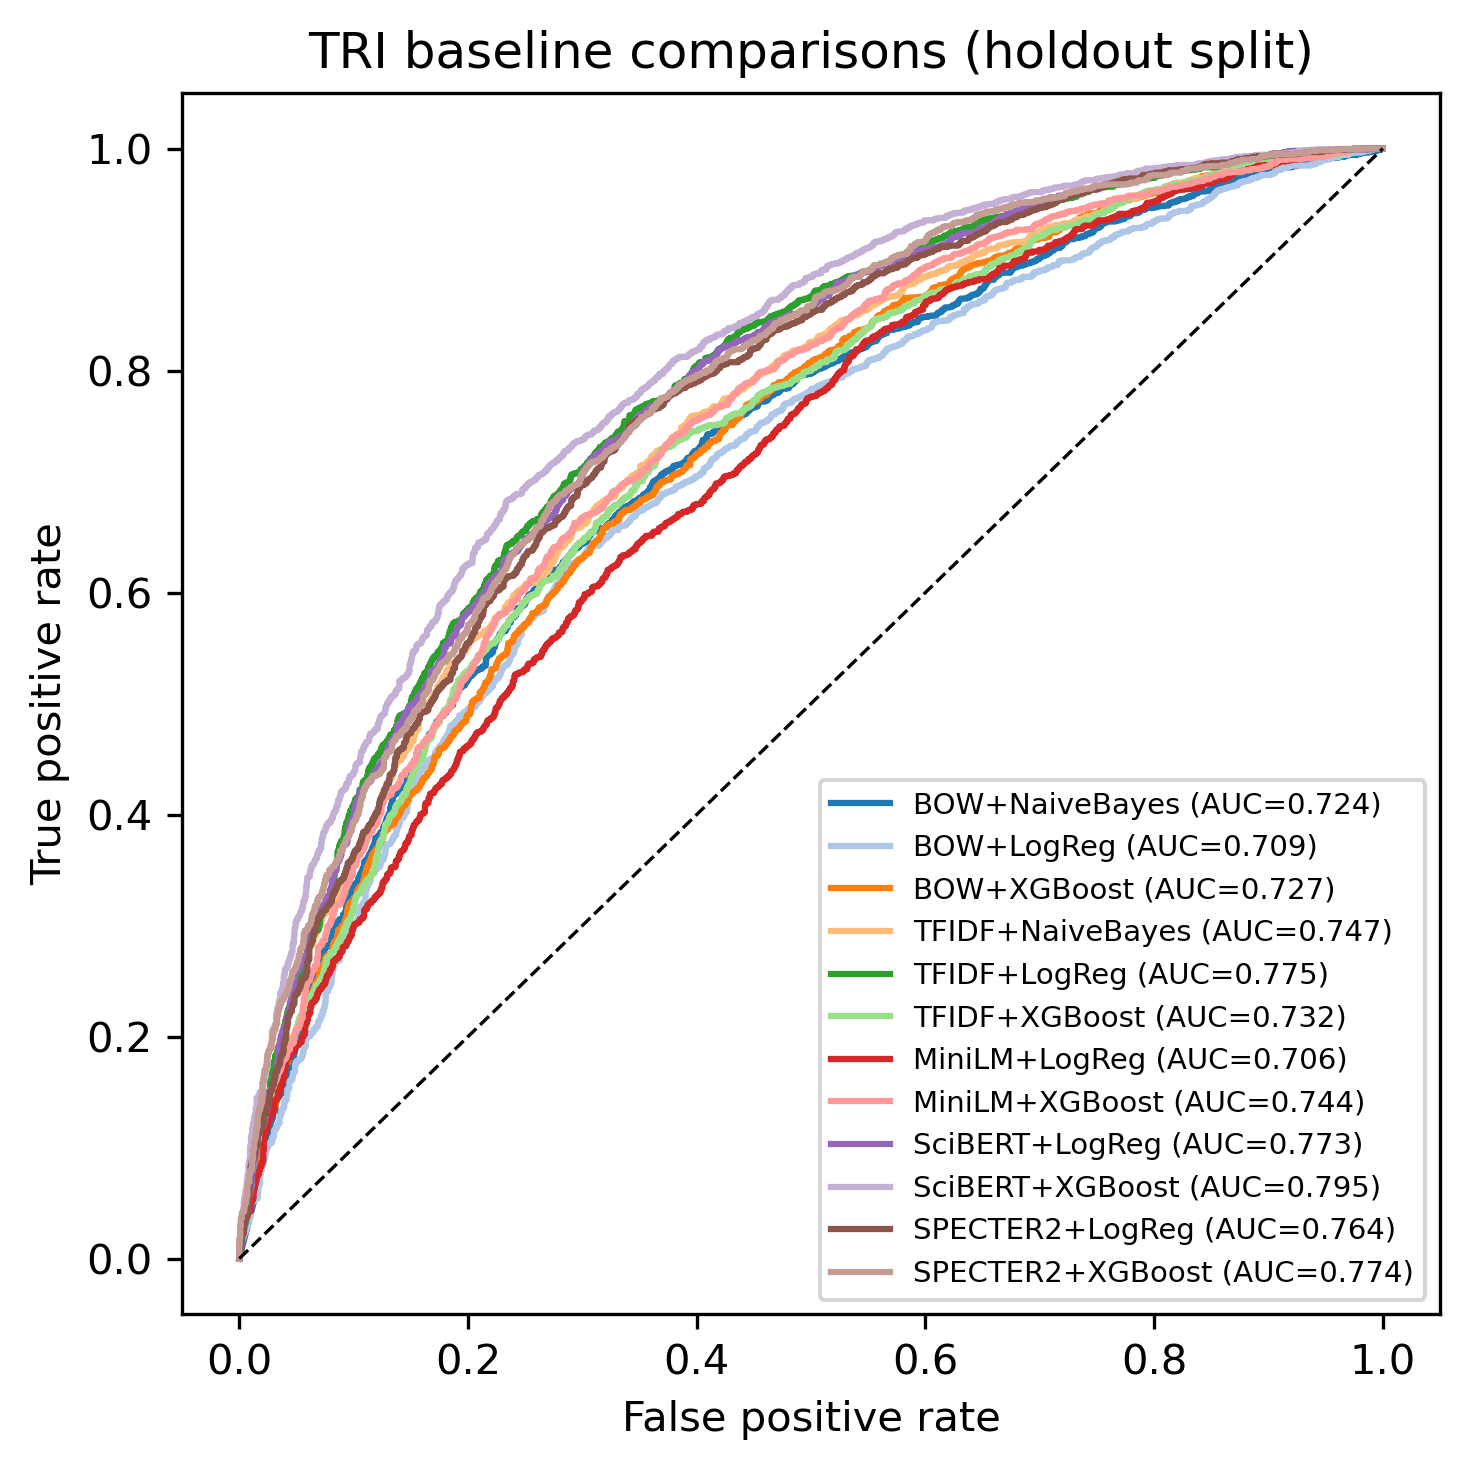

Saved results to outputFiles/: results_table.csv, bootstrap_comparison.json, roc_curves.pdf


In [14]:
plt.figure(figsize=(5, 5))
for i, (key, p_test) in enumerate(holdout.items()):
    fpr, tpr, _ = roc_curve(y[te], p_test)
    plt.plot(fpr, tpr, lw=1.5, color = list(cm.get_cmap('tab20').colors)[i],
             label=f"{key} (AUC={roc_auc_score(y[te], p_test):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("TRI baseline comparisons (holdout split)")
plt.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "roc_curves.pdf"), dpi=300)
plt.show()
print(f"Saved results to {OUTDIR}/: results_table.csv, "
      "bootstrap_comparison.json, roc_curves.pdf")